# Iteration 2 · DINO as a re-ranker of the shortlist

**Question.** DINO failed as its own search map (`Dino_Coarse.ipynb`). What if the non-DINO method picks the 50 best places first, and DINO only re-orders those 50 before the best 25 go to the fine stage?

Blocks used: `train/coarse_methods/dino_rerank.py` (`shortlist_peaks`, `dino_candidate_scores`, `rerank_peaks`), `train/coarse_methods` (the first-stage methods). Coarse stage only; the fine stage is not run here.

# Part 1 · Settings

In [1]:
import os, sys, json, math, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not ((ROOT / "train").exists() and (ROOT / "src").exists()):
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)

N_PHOTOS = 500          # the loader gives all official photos it has (379)
SEED = 7
SHORTLIST = 50          # peaks taken from the first stage
WEIGHTS = [0.25, 0.5, 1, 2, 4, 100]     # 100 = DINO alone decides inside the shortlist
FIRST_STAGES = ["edge_zncc", "fused"]
plt.rcParams["figure.dpi"] = 90

# Part 2 · Photos, map, first-stage methods, DINO encoder

In [2]:
from train.datasets import photo_sets
from header import settings
from train import config
from train.features.edge import EdgeFamily
from train.features.mind import MindFamily
from train.features.learned_family import LearnedFamily
from train.features.dino_tokens import load_dino
from train.coarse_methods import build_methods
from train.coarse_methods.inputs import make_inputs
from train.coarse_methods.dino_rerank import shortlist_peaks, dino_candidate_scores, rerank_peaks
from src.image_processing.geometry import render_query
from src.image_processing.map_store import build_map_store
from coarse_search.fusion import load_model

loaded = photo_sets.load_official_photos(N_PHOTOS, SEED)
test_set, camera, satellite_map = loaded["test_set"], loaded["camera"], loaded["satellite_map"]
store = build_map_store(satellite_map)
level_images = store["levels"]
families = {"edge": EdgeFamily(store), "mind": MindFamily(store, settings.LEVELS),
            "learned": LearnedFamily(store, settings.LEVELS, config.OUT_DIR / "models" / "f4.pt")}
names = ["edge_zncc", "edge_cosine", "edge_mag", "edge_zncc_w", "mind_zncc", "learned_zncc"]
best = json.load(open(config.OUT_DIR / "state.json"))["results"]["fusion_best"]
model = load_model(config.OUT_DIR / "models" / "fusion" / (best["tag"] + ".pt")).to(settings.DEVICE).eval()
methods = build_methods(["edge_zncc"], fused_models={"fused": (model, best["subset"])})
encoder = load_dino()
print(len(test_set.items), "photos; first stages:", FIRST_STAGES)

level 3: 0.85 m/pixel, picture 7812 x 4893, map coverage 70%
level 4: 1.20 m/pixel, picture 5524 x 3460, map coverage 70%
level 5: 1.70 m/pixel, picture 3906 x 2446, map coverage 70%
level 6: 2.40 m/pixel, picture 2762 x 1730, map coverage 70%
level 7: 3.39 m/pixel, picture 1953 x 1223, map coverage 70%
map store ready, took 14 s


379 photos; first stages: ['edge_zncc', 'fused']


# Part 3 · One photo, step by step

First stage gives 50 peaks. DINO scores each one with a map window cut exactly at the peak. Green star = truth; peaks are drawn by first-stage rank; colour = DINO dense score.

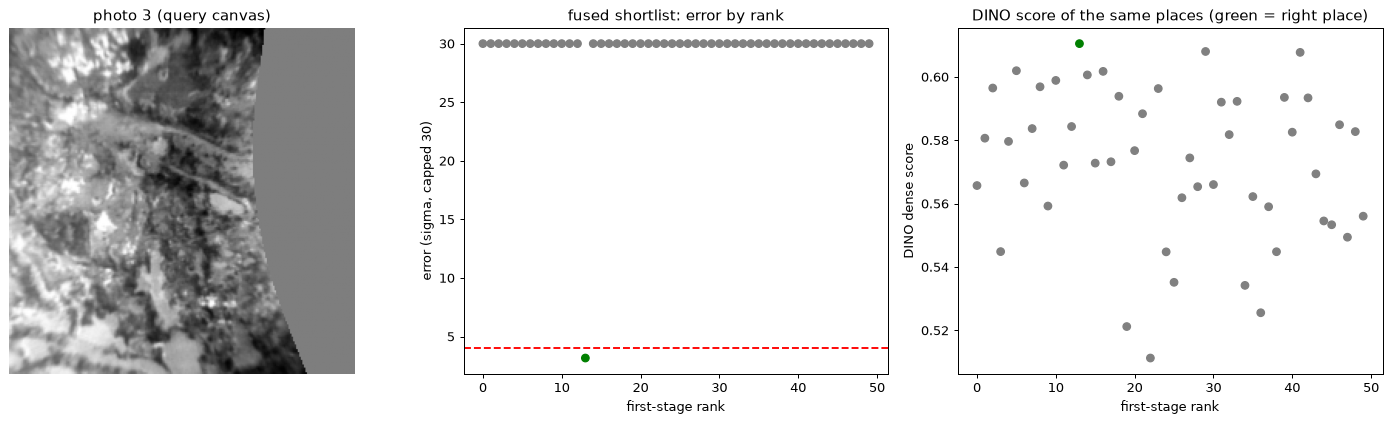

fused rank-1 error 377.5 sigma -> after DINO re-rank 3.2 sigma


In [3]:
def errors_in_sigma(peaks, i):
    truth, sigma = test_set.truths[i], test_set.sigmas[i]
    return np.array([math.hypot(r[1] - truth[0], r[2] - truth[1]) / sigma if r[1] < 1e8 else 1e9 for r in peaks])

def run_photo(i):
    level = int(test_set.query_levels[i])
    canvas, valid = render_query(test_set.items[i], camera, level)
    inputs = make_inputs(canvas, valid, level, test_set.priors[i], families, names)
    out = {}
    for label in FIRST_STAGES:
        short = shortlist_peaks(methods[label](inputs), inputs["geometry"], SHORTLIST)
        pooled, dense = dino_candidate_scores(encoder, canvas, valid, level_images, level, short)
        out[label] = dict(peaks=short, pooled=pooled, dense=dense, err=errors_in_sigma(short, i))
    return canvas, out

# a photo where the first stage is wrong at rank 1 but right somewhere in the 50, if there is one
for i in range(len(test_set.items)):
    canvas, one = run_photo(i)
    e = one["fused"]["err"]
    if e[0] > 4 and e.min() <= 4:
        break
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].imshow(canvas, cmap="gray"); axes[0].set_title("photo %d (query canvas)" % i); axes[0].axis("off")
sh = one["fused"]
axes[1].scatter(range(len(sh["err"])), np.minimum(sh["err"], 30), c=np.where(sh["err"] <= 4, "green", "gray"))
axes[1].axhline(4, color="red", ls="--"); axes[1].set_xlabel("first-stage rank"); axes[1].set_ylabel("error (sigma, capped 30)"); axes[1].set_title("fused shortlist: error by rank")
axes[2].scatter(range(len(sh["err"])), sh["dense"], c=np.where(sh["err"] <= 4, "green", "gray"))
axes[2].set_xlabel("first-stage rank"); axes[2].set_ylabel("DINO dense score"); axes[2].set_title("DINO score of the same places (green = right place)")
plt.tight_layout(); plt.show()
after = rerank_peaks(sh["peaks"], sh["dense"], 100.0)
print("fused rank-1 error %.1f sigma -> after DINO re-rank %.1f sigma" % (sh["err"][0], errors_in_sigma(after, i)[0]))

# Part 4 · All photos

In [4]:
records = []
start = time.time()
for i in range(len(test_set.items)):
    try:
        _, one = run_photo(i)
    except Exception as error:
        print("photo %d failed: %s" % (i, str(error)[:100])); continue
    records.append(one)
    if i % 50 == 0:
        print("photo %d of %d, %.0f s" % (i + 1, len(test_set.items), time.time() - start))
print(len(records), "photos done")

photo 1 of 379, 2 s
photo 51 of 379, 41 s
photo 101 of 379, 82 s
photo 151 of 379, 121 s
photo 201 of 379, 162 s
photo 251 of 379, 202 s
photo 301 of 379, 242 s
photo 351 of 379, 284 s
379 photos done


In [5]:
def order_after(entry, weight, score):
    out = rerank_peaks(entry["peaks"], entry[score], weight, keep=len(entry["peaks"]))
    return np.array([int(np.argmin(np.abs(entry["peaks"][:, 1] - r[1]) + np.abs(entry["peaks"][:, 2] - r[2]))) for r in out])

def stats(label, score=None, weight=0):
    top1, ceil25 = [], []
    for record in records:
        entry = record[label]
        err = entry["err"] if score is None else entry["err"][order_after(entry, weight, score)]
        top1.append(err[0] <= 4); ceil25.append(err[:25].min() <= 4)
    return np.array(top1), np.array(ceil25)

rows = []
for label in FIRST_STAGES:
    t, c = stats(label); rows.append({"first stage": label, "re-rank": "none", "top-1": t.mean(), "ceiling@25": c.mean()})
    for score in ("pooled", "dense"):
        for weight in WEIGHTS:
            t, c = stats(label, score, weight)
            rows.append({"first stage": label, "re-rank": "%s w=%g" % (score, weight), "top-1": t.mean(), "ceiling@25": c.mean()})
table = pd.DataFrame(rows)
display(table.round(3))

,first stage,re-rank,top-1,ceiling@25
0,edge_zncc,none,0.802,0.897
1,edge_zncc,pooled w=0.25,0.813,0.905
2,edge_zncc,pooled w=0.5,0.815,0.908
3,edge_zncc,pooled w=1,0.828,0.913
4,edge_zncc,pooled w=2,0.839,0.916
5,edge_zncc,pooled w=4,0.828,0.916
6,edge_zncc,pooled w=100,0.346,0.910
7,edge_zncc,dense w=0.25,0.823,0.908
8,edge_zncc,dense w=0.5,0.844,0.913
9,edge_zncc,dense w=1,0.873,0.916


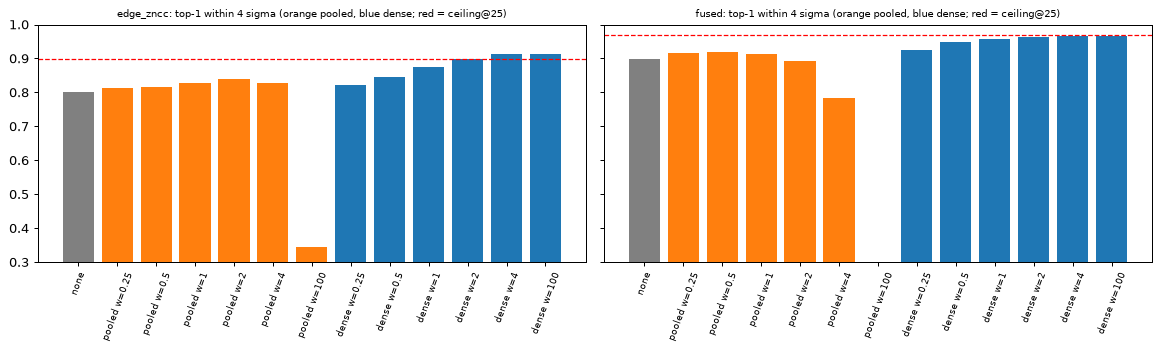

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axis, label in zip(axes, FIRST_STAGES):
    part = table[table["first stage"] == label].reset_index(drop=True)
    axis.bar(range(len(part)), part["top-1"], color=["gray"] + ["tab:orange"] * len(WEIGHTS) + ["tab:blue"] * len(WEIGHTS))
    axis.set_xticks(range(len(part))); axis.set_xticklabels(part["re-rank"], rotation=70, fontsize=7)
    axis.axhline(part["ceiling@25"][0], color="red", ls="--", lw=1)
    axis.set_title("%s: top-1 within 4 sigma (orange pooled, blue dense; red = ceiling@25)" % label, fontsize=8)
axes[0].set_ylim(0.3, 1.0)
plt.tight_layout(); plt.show()

# Part 5 · Is the gain real? Paired bootstrap, DINO alone inside the shortlist

In [7]:
rng = np.random.default_rng(0)
rows = []
for label in FIRST_STAGES:
    base, _ = stats(label)
    new, _ = stats(label, "dense", 100.0)
    diffs = []
    for _ in range(5000):
        pick = rng.integers(0, len(base), len(base))
        diffs.append(new[pick].mean() - base[pick].mean())
    low, high = np.percentile(diffs, [2.5, 97.5])
    rows.append({"first stage": label, "top-1 before": base.mean(), "top-1 after": new.mean(), "difference": new.mean() - base.mean(),
                 "95% low": low, "95% high": high, "photos fixed": int((new & ~base).sum()), "photos broken": int((base & ~new).sum())})
display(pd.DataFrame(rows).round(3))

,first stage,top-1 before,top-1 after,difference,95% low,95% high,photos fixed,photos broken
0,edge_zncc,0.802,0.913,0.111,0.079,0.142,42,0
1,fused,0.897,0.966,0.069,0.045,0.095,26,0


**How to read it.** `ceiling@25` does not move: DINO re-orders inside the shortlist and cannot add places. The change is in rank 1. The fine stage tries all 25 peaks, so what this buys after the fine stage must be measured with the fine stage (next notebook).